<a href="https://colab.research.google.com/github/satyamchaurasia-4444/RNN-IMDB-Movie-Review-Sentiment-Analysis/blob/main/RNN_imdb_movie_sentiment_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df=pd.read_csv('/content/drive/MyDrive/PROJECTS/RNN IMDB movie/IMDB Dataset.csv')
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [2]:
df.shape

(50000, 2)

In [3]:
df=df.sample(n=5000,random_state=42).reset_index()

In [4]:
df.head()

,index,review,sentiment
0,33553,I really liked this Summerslam due to the look...,positive
1,9427,Not many television shows appeal to quite as m...,positive
2,199,The film quickly gets to a major chase scene w...,negative
3,12447,Jane Austen would definitely approve of this o...,positive
4,39489,Expectations were somewhat high for me when I ...,negative


In [5]:
df['sentiment'].value_counts()

,count
sentiment,
positive,2519
negative,2481


In [6]:
# Preprocessing

In [7]:
import re
import nltk
from nltk.corpus import stopwords
import pandas as pd

nltk.download('stopwords')
stopwords=stopwords.words('english')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [8]:
def cleaned_data(text):
  text=text.lower()

  text=re.sub(r'<.*?>','',text) # remove html tags

  text=re.sub(r'[^\w\s]','',text)

  text=re.sub(r'\d+','',text)
  words=[]
  for word in text.split():
    if word not in stopwords:
      words.append(word)

  text=' '.join(words)
  return text

In [9]:
df['Cleaned_text']=df['review'].apply(cleaned_data)

In [10]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df['encoded_sentiment'] = label_encoder.fit_transform(df['sentiment'])

In [11]:
df.head()

,index,review,sentiment,Cleaned_text,encoded_sentiment
0,33553,I really liked this Summerslam due to the look...,positive,really liked summerslam due look arena curtain...,1
1,9427,Not many television shows appeal to quite as m...,positive,many television shows appeal quite many differ...,1
2,199,The film quickly gets to a major chase scene w...,negative,film quickly gets major chase scene ever incre...,0
3,12447,Jane Austen would definitely approve of this o...,positive,jane austen would definitely approve onegwynet...,1
4,39489,Expectations were somewhat high for me when I ...,negative,expectations somewhat high went see movie thou...,0


In [12]:
#Encoding

In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenizer setup
tokenizer = Tokenizer(num_words=10000, oov_token="")
tokenizer.fit_on_texts(df['Cleaned_text'])

# Convert text to sequences (integer representation)
sequences = tokenizer.texts_to_sequences(df['Cleaned_text'])


In [14]:
tokenizer.word_index

{'': 1,
 'movie': 2,
 'film': 3,
 'one': 4,
 'like': 5,
 'good': 6,
 'even': 7,
 'would': 8,
 'time': 9,
 'really': 10,
 'see': 11,
 'story': 12,
 'get': 13,
 'much': 14,
 'well': 15,
 'people': 16,
 'great': 17,
 'first': 18,
 'bad': 19,
 'also': 20,
 'films': 21,
 'dont': 22,
 'made': 23,
 'make': 24,
 'movies': 25,
 'characters': 26,
 'could': 27,
 'way': 28,
 'think': 29,
 'many': 30,
 'love': 31,
 'watch': 32,
 'two': 33,
 'never': 34,
 'character': 35,
 'best': 36,
 'seen': 37,
 'acting': 38,
 'little': 39,
 'show': 40,
 'plot': 41,
 'life': 42,
 'know': 43,
 'better': 44,
 'ever': 45,
 'say': 46,
 'man': 47,
 'still': 48,
 'end': 49,
 'scene': 50,
 'scenes': 51,
 'something': 52,
 'go': 53,
 'actors': 54,
 'im': 55,
 'watching': 56,
 'didnt': 57,
 'thing': 58,
 'work': 59,
 'another': 60,
 'doesnt': 61,
 'back': 62,
 'actually': 63,
 'funny': 64,
 'real': 65,
 'years': 66,
 'nothing': 67,
 'though': 68,
 'makes': 69,
 'cant': 70,
 'look': 71,
 'director': 72,
 'every': 73,
 'lot

In [15]:
import numpy as np
lengths=[]

for seq in sequences:
  lengths.append(len(seq))

In [16]:
lengths
np.max(lengths)

np.int64(582)

In [17]:
# Pad the sequence

padding_sequences=pad_sequences(sequences,maxlen=582,padding='post')

In [18]:
# Train a simple rnn model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,Dense,Dropout,SimpleRNN
from tensorflow.keras.optimizers import Adam

model=Sequential()
model.add(Embedding(input_dim=10000,output_dim=64))
model.add(SimpleRNN(128,activation='tanh',return_sequences=True))
model.add(Dropout(0.5))
model.add(SimpleRNN(64,activation='tanh'))
model.add(Dropout(0.5))
model.add(Dense(1,activation='sigmoid'))

In [19]:
# compile the model

model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])

In [20]:
history=model.fit(padding_sequences,df['encoded_sentiment'],epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 197ms/step - accuracy: 0.5132 - loss: 0.7734 - val_accuracy: 0.5150 - val_loss: 0.6939
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.5063 - loss: 0.7893 - val_accuracy: 0.4930 - val_loss: 0.6998
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.5017 - loss: 0.7765 - val_accuracy: 0.4970 - val_loss: 0.6985
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.4942 - loss: 0.7599 - val_accuracy: 0.5210 - val_loss: 0.6909
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.4922 - loss: 0.7414 - val_accuracy: 0.5340 - val_loss: 0.6908
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.5008 - loss: 0.7243 - val_accuracy: 0.4780 - val_loss: 0.7032
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.5013 - loss: 0.7194 - val_accuracy: 0.5220 - val_loss: 0.6922
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - accuracy: 0.5023 - loss: 0.7137 - val_accuracy: 0.4910 -

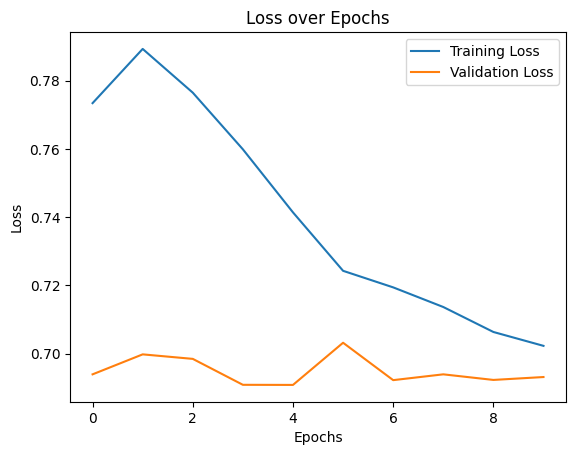

In [21]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_pred=model.predict(padding_sequences)

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step


In [23]:
y_pred=(y_pred>0.5).astype(int)

In [24]:
cm = confusion_matrix(df['encoded_sentiment'], y_pred)
print('Confusion matrix:\n',cm)

Confusion matrix:
 [[   0 2481]
 [   0 2519]]


In [25]:
cr=classification_report(df['encoded_sentiment'], y_pred)
print('classification_report:\n',cr)

classification_report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00      2481
           1       0.50      1.00      0.67      2519

    accuracy                           0.50      5000
   macro avg       0.25      0.50      0.34      5000
weighted avg       0.25      0.50      0.34      5000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [26]:
# Save the model

model.save('sentiment_rnn_model.h5')

In [27]:
# Load model

from tensorflow.keras.models import load_model

loaded_model = load_model('sentiment_rnn_model.h5')

In [28]:
# Prediction System

In [29]:
def predict_sentiment(sentence):
  sentence = cleaned_data(sentence)
  sequence = tokenizer.texts_to_sequences([sentence])
  pad_sequence = pad_sequences(sequence, maxlen=582, padding='post')
  prediction = loaded_model.predict(pad_sequence)

  prediction = loaded_model.predict(pad_sequence)
  if prediction > 0.5:
        return "Positive"
  else:
        return "Negative"




In [30]:
# Test the prediction system
test_sentence = "I love this product!"
print(f"Sentiment: {predict_sentiment(test_sentence)}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
Sentiment: Positive
